# LightGBM on TF-IDF

This notebook trains a LightGBM model on the same TF-IDF features and train/test split as the Logistic Regression baseline. A boosted model of 200 trees can't be read directly, so we explain it with post-hoc methods.

The steps: global importance (grouped PFI, TreeSHAP) → feature effects (ALE) → heterogeneity (ICE, centered ICE) → individual decisions (SP-LIME, LIME, SHAP). Grouped PFI and ALE are used instead of plain PFI and PDP because several top terms are correlated (Section 8).

## 1. Setup

In [1]:
import os, sys
if not os.path.exists("preprocessing.py"):                             
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))  
sys.path.insert(0, os.getcwd())             

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,BREAKING: GOP Chairman Grassley Has Had Enough...,"Donald Trump s White House is in chaos, and th...",fake,1
1,Failed GOP Candidates Remembered In Hilarious ...,Now that Donald Trump is the presumptive GOP n...,fake,1
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,Mike Pence is a huge homophobe. He supports ex...,fake,1
3,California AG pledges to defend birth control ...,California Attorney General Xavier Becerra sai...,real,0
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,az rancher living u mexico border destroy nanc...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of this. To them, it s  fake 

PROCESSED:
 breaking gop chairman grassley enough demand trump jr testimony donald trump white house chaos trying cover russia problem mounting hour refuse acknowledge problem surrounding fake news hoax however fact bear thing differently seems crack congressional public leadership chuck grassley r iowa head se


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (38633, 5000)


Same TF-IDF settings as the baseline (see its Section 4). This cell only shows the size of the matrix; the TF-IDF the model uses is fitted again in the next step, on the training articles only.

## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (30906, 5000)
Test shape: (7727, 5000)

Train class balance:
 label_encoded
0    0.549
1    0.451
Name: proportion, dtype: float64

Test class balance:
 label_encoded
0    0.548
1    0.452
Name: proportion, dtype: float64


## 6. Train LightGBM

LightGBM builds trees one after another, each fixing the mistakes of the trees before it. We keep the trees small (depth 4, at most 15 leaves, at least 50 articles per leaf) and the learning rate low, so the model memorizes less of the training data and is quick to explain with TreeSHAP.

In [7]:
lgbm = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=4,
    min_child_samples=50,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)
lgbm.fit(X_train, y_train)
y_pred = lgbm.predict(X_test)

## 7. Validate Predictive Performance

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, lgbm.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")

from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_test, lgbm.predict_proba(X_test)[:, 1])
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.97      0.99      0.98      4238
        fake       0.99      0.97      0.98      3489

    accuracy                           0.98      7727
   macro avg       0.98      0.98      0.98      7727
weighted avg       0.98      0.98      0.98      7727

Fake-class recall (test):  0.9659
Fake-class recall (train): 0.9720   <- large gap vs test = overfitting
Accuracy (test): 0.9801
ROC AUC (test): 0.9978
Share of test articles predicted fake: 0.441


LightGBM catches 96.6% of fake articles (recall = 0.9659) with an accuracy of 98.0%, the same as the baseline logistic regression (0.980). Its ROC AUC is 0.998, so it ranks almost every fake article above almost every real one. It calls 44.1% of test articles fake, close to the real share of 45.2%.

Training recall is 0.9720 against 0.9659 on test, a very small gap, so the small trees and low learning rate keep it from memorising the training data.

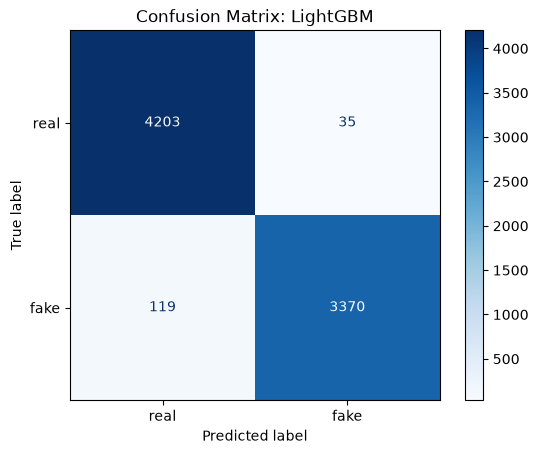

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: LightGBM")
plt.show()

- True Positive, correctly caught fake article: 3,370
- False Negative, fake article predicted as real: 119
- False Positive, real article predicted as fake: 35
- True Negative, correctly identified real article: 4,203

99.0% of its "fake" flags are right (precision = 0.990). Compared with the baseline, it misses slightly more fakes (119 vs 108) but raises fewer false alarms (35 vs 44). Compared with the Random Forest, it misses about half as many fakes (119 vs 228) with almost the same number of false alarms. It's the strongest of the tree models.

## 8. Top-K Terms and Multicollinearity Check

With 5,000 terms, looking at every term isn't practical: ALE and ICE would need thousands of plots, and a 5,000 × 5,000 correlation matrix can't be read. So we focus on the 30 terms most linked to the label (K = 30), ranked by chi-squared on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. Higher means a stronger link to the label, but it doesn't show the direction. We use it because it doesn't depend on any model, so every notebook shares the same list. TF-IDF weights aren't counts, so the scores are only used for ranking, not as significance tests.

In [10]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,video,429.735134
1,said,354.357520
2,image,351.657391
3,via,273.043116
4,featured,245.148761
5,com,236.464647
6,hillary,229.692337


The top seven are video, said, image, via, featured, com and hillary, the same list as in the other notebooks since chi-squared doesn't depend on the model. Five of them (video, image, via, featured, com) are source fingerprints: embedded videos, photo credits and links on fake sites. said is Reuters' writing style, and hillary is the partisan naming fake sites use.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [11]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

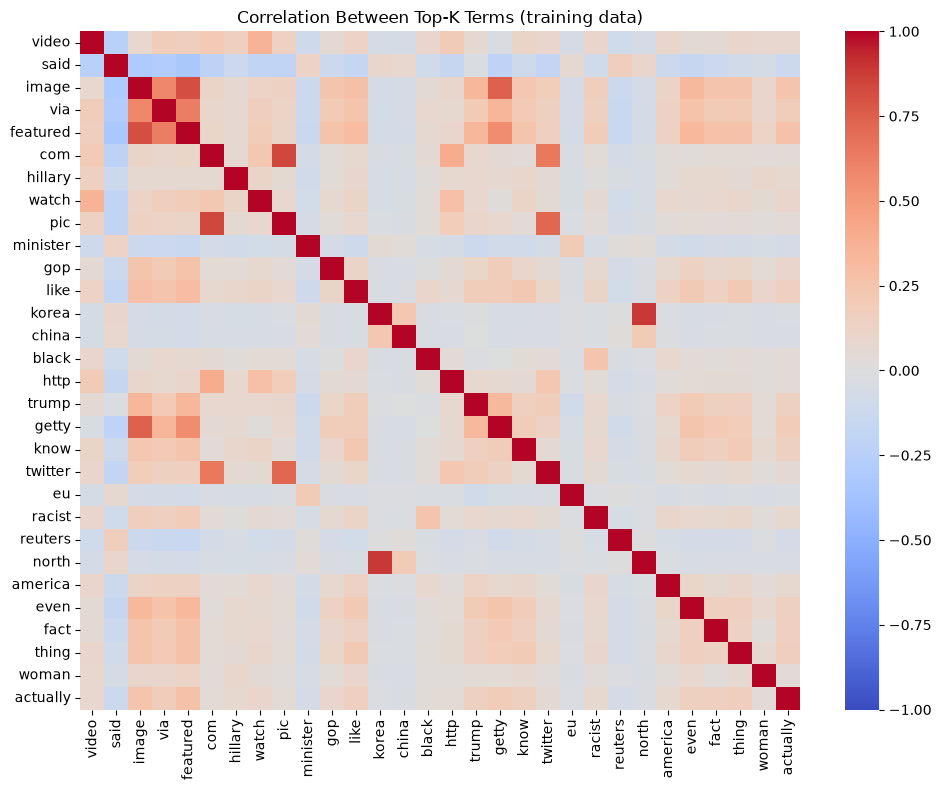

Pairs with |correlation| > 0.5:
korea     north       0.885267
com       pic         0.842176
image     featured    0.814060
          getty       0.743669
pic       twitter     0.721554
com       twitter     0.649922
via       featured    0.628802
image     via         0.579483
featured  getty       0.562061
dtype: float64


In [12]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

Most cells are close to 0, but nine pairs go above 0.5, and they form three groups:

- **Photo credits:** image, featured, getty and via (0.56 to 0.81), all from "Featured image via Getty Images."
- **Links:** com, pic and twitter (0.65 to 0.84), from embedded tweets ("pic.twitter.com").
- **A name:** north and korea (0.89).

These words come as a package: an article that has one of them usually has the others. This rules out two explanation methods that assume the words are independent, plain PFI and PDP. We use grouped PFI (9.1) and ALE (10) instead, and ICE only uses terms outside these groups (11). Each section explains why. The check only covers the top 30 terms and linear relationships, so other dependencies may still exist.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Grouped Permutation Feature Importance (PFI)

PFI shuffles a term's values across the test articles and measures how much Fake-class recall drops (averaged over 5 repeats). A big drop means the model relies on that term to catch fakes.

**Why grouped and not plain PFI:** plain PFI shuffles one term at a time. If we shuffle only via, the article still has image, featured and getty, so the model can still spot the photo credit and barely notices. Each term then looks unimportant, even though the photo credit as a whole matters a lot. Grouped PFI shuffles correlated terms together, with the same row order, so the whole group is removed at once. Terms that aren't correlated with anything are still shuffled on their own, so for them it's the same as plain PFI.

That turns the 30 top terms into 24 units: three groups (image, via, featured, getty; com, pic, twitter; korea, north) and 21 single terms.

In [13]:
def permutation_recall_drop(model, X_dense, y_true, groups, n_repeats=5, seed=RANDOM_STATE):
    """Shuffle each group of terms TOGETHER (same row order). A group is either a single term
    or a set of correlated terms, so correlated terms cannot stand in for each other."""
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for terms in groups:
        cols = [tfidf.vocabulary_[t] for t in terms]
        original = X_dense[:, cols].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, cols] = original[rng.permutation(len(original))]
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, cols] = original
        rows.append((", ".join(terms), np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

# Merge the correlated pairs from Section 8 into groups (image-featured + image-getty -> one group)
term_groups = []
for a, b in high_pairs.index:
    linked = [g for g in term_groups if a in g or b in g]
    merged = {a, b}.union(*linked)
    term_groups = [g for g in term_groups if g not in linked] + [merged]

# Each correlated group is shuffled as one unit; every other top term on its own
pfi_groups = []
for t in top_terms:
    group = next((g for g in term_groups if t in g), {t})
    terms = [u for u in top_terms if u in group]          # keep chi-squared order
    if terms not in pfi_groups:
        pfi_groups.append(terms)

print(f"{len(top_terms)} top terms -> {len(pfi_groups)} PFI units")
base_recall, pfi_df = permutation_recall_drop(lgbm, X_test_dense, y_test, pfi_groups)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

30 top terms -> 24 PFI units
Recall before shuffling: 0.9659


,term,mean_recall_drop,std
2,"image, via, featured, getty",0.060648,0.001827
1,said,0.024018,0.001466
0,video,0.012726,0.001637
17,reuters,0.011235,0.001665
6,minister,0.004414,0.001423
4,hillary,0.002064,0.000556
7,gop,0.000917,0.000556


The photo-credit group matters most by far: shuffling it drops recall by 0.061, about 212 of the 3,489 fake test articles. said comes second at 0.024 (about 84 articles), then video (0.013, about 44) and reuters (0.011, about 39). minister, hillary and gop are small (2 to 15 articles).

This is a big difference from the Random Forest, where said came first and the photo-credit group cost only 0.019. LightGBM leans about three times as hard on the photo credit, a piece of page layout rather than anything the article says.

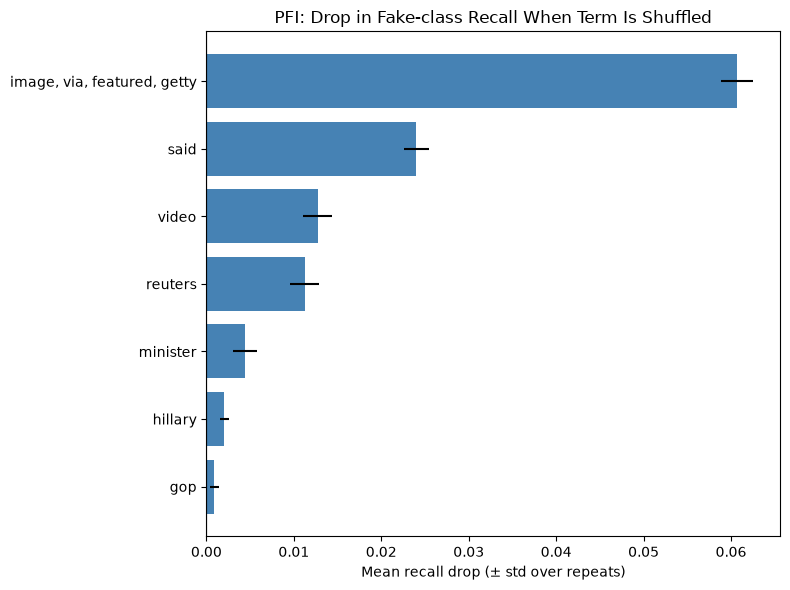

In [14]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The photo-credit group stands far ahead of everything else, with a narrow error bar. said, video and reuters follow, all clearly above zero. The smaller bars (minister, hillary, gop) are also above zero, but gop's error bar comes close to it. The check below tests them against chance.

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [15]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)
_, pfi_null = permutation_recall_drop(lgbm, X_test_dense, y_test, [[feature_names[i]] for i in other_idx])
print(pfi_null["mean_recall_drop"].describe())

count    30.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: mean_recall_drop, dtype: float64


Every one of the 30 random terms has a drop of exactly zero. LightGBM's small trees only split on a limited set of terms, and none of these random ones is among them, so shuffling them can't change any prediction. Every top unit, even gop at 0.0009 (about 3 articles), is above that, so their effects are real, though gop's is very small.

### 9.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term, starting from the model's average output. TreeSHAP calculates these values exactly for tree models. They are computed for the same 200 test articles as in the other notebooks and then averaged.

For LightGBM, SHAP values are in log-odds, not probability. Positive values push toward fake and negative values toward real. Near a probability of 0.5, a change of 0.1 in log-odds is about 2.5 percentage points.

Further from 0.5, the same change moves the probability much less: at 0.99, 0.1 in log-odds is only about 0.1 points. That's why articles the model is already sure about barely move in the ICE plots below, even when a word has a large log-odds effect.

In [16]:
explainer_shap = shap.TreeExplainer(lgbm)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 5000)


c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


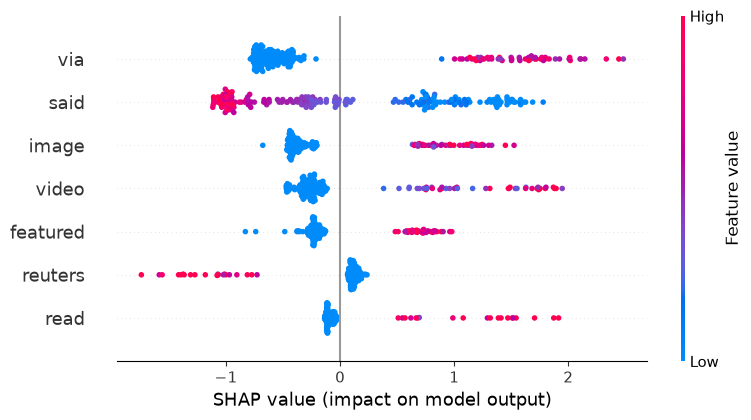

In [17]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [18]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
4789,via,0.867118
3905,said,0.796718
2206,image,0.524081
4793,video,0.468371
1705,featured,0.330275
3801,reuters,0.231374
3605,read,0.197211


Each dot is one article: its position shows how much a term pushed the output toward fake (right) or real (left), in log-odds, and its color shows the term's weight (red high, blue low or absent).

via is the strongest term. Articles that contain it are pushed toward fake by about 1 to 2.5 log-odds, and articles without it are pushed toward real by about 0.7, so its absence matters too. said works the other way: frequent use pushes toward real (about −1), and articles without it are pushed toward fake by up to about 1.8. image, video, featured and read ("READ MORE" links) push toward fake when present, and reuters pushes strongly toward real (about −0.8 to −1.8) in the articles that mention it.

These effects are much bigger than in the Random Forest. LightGBM is very sure about most articles, so single words move its output a long way.

SHAP and grouped PFI agree on the main picture: the photo credit (led by via) and said are the two biggest signals, and video and reuters come next.

## 10. Feature Effects (ALE)

ALE shows how the predicted probability of fake changes as one term's weight goes up, so it shows the direction and size of each term's effect.

**Why ALE and not PDP:** PDP sets a term to each value in every article while leaving the rest of the article alone. For correlated terms that creates articles that can't exist, such as a photo credit with "image" but no "featured" or "getty", and the curve then describes those fake articles instead of real ones. ALE avoids this. It cuts the term's weights into small intervals and, in each interval, only uses the articles whose weight is actually in that interval. It measures how the prediction changes across that small step, then adds the steps up. 0 on the y-axis means the average prediction.

We plot the six top chi-squared terms: video, said, image, via, featured and com. Most articles don't contain a given term, so the first interval runs from 0 (absent) to the smallest weight at which the term shows up.

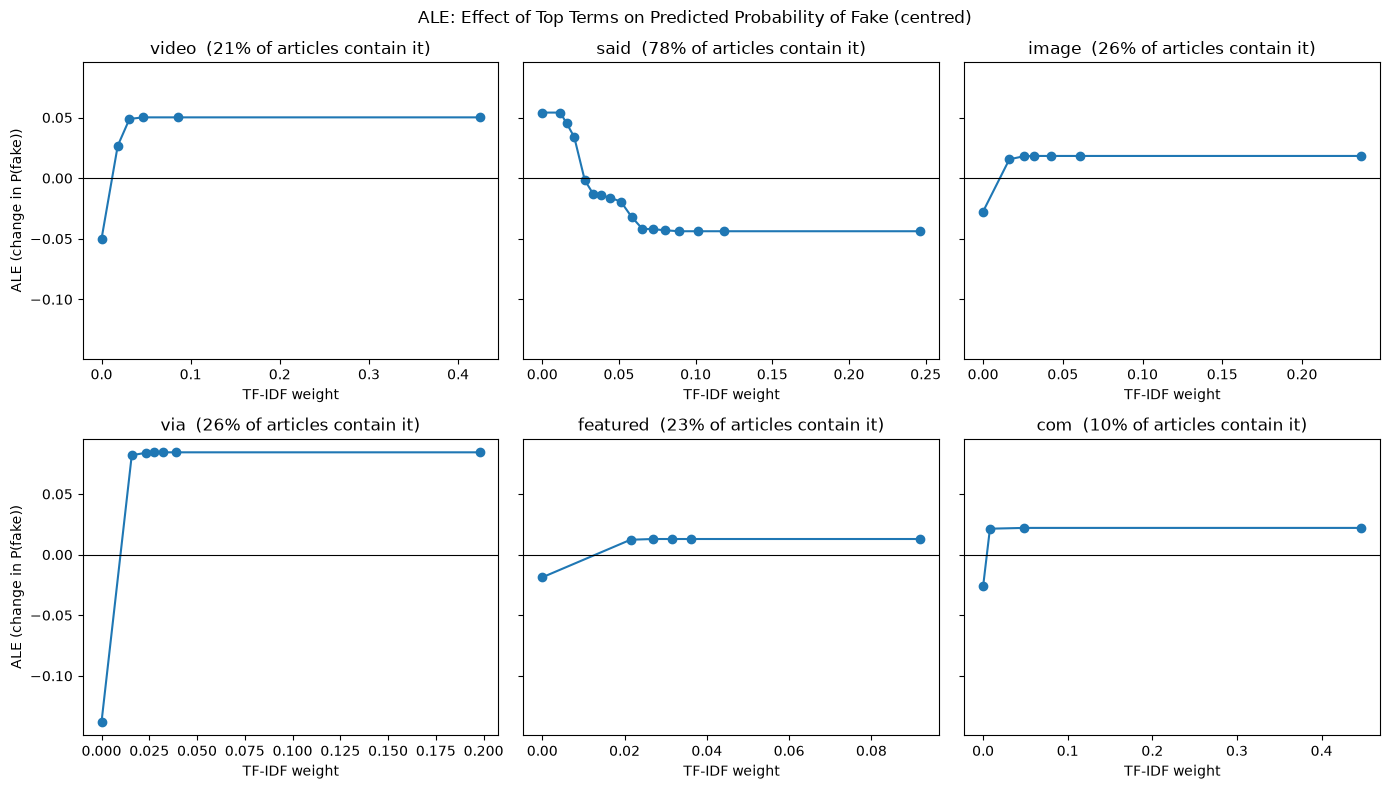

In [19]:
def ale_1d(predict, X, col, n_bins=20):
    """First-order ALE for one column. Bins are quantiles of the column, so most of the
    mass at weight 0 collapses into one edge. Returns bin edges and centred ALE values."""
    x = X[:, col]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 2:
        return edges, np.zeros(len(edges))
    # article in interval (edges[k-1], edges[k]] -> bin k; articles exactly at the lowest edge go to bin 1
    bin_idx = np.clip(np.searchsorted(edges, x, side="left"), 1, len(edges) - 1)
    effects = np.zeros(len(edges) - 1)
    counts = np.zeros(len(edges) - 1)
    for k in range(1, len(edges)):
        rows = X[bin_idx == k]
        if len(rows) == 0:
            continue
        lo, hi = rows.copy(), rows.copy()
        lo[:, col], hi[:, col] = edges[k - 1], edges[k]
        effects[k - 1] = (predict(hi) - predict(lo)).mean()   # local effect, using only articles in this bin
        counts[k - 1] = len(rows)
    ale = np.concatenate([[0.0], np.cumsum(effects)])         # accumulate the local effects
    mids = (ale[:-1] + ale[1:]) / 2
    ale -= (mids * counts).sum() / counts.sum()               # centre so the average effect is 0
    return edges, ale

ale_terms = list(top_terms[:6])
predict_fake = lambda X: lgbm.predict_proba(X)[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, term in zip(axes.ravel(), ale_terms):
    col = tfidf.vocabulary_[term]
    edges, ale = ale_1d(predict_fake, X_test_dense, col)
    ax.plot(edges, ale, marker="o")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{term}  ({(X_test_dense[:, col] > 0).mean():.0%} of articles contain it)")
    ax.set_xlabel("TF-IDF weight")
for ax in axes[:, 0]:
    ax.set_ylabel("ALE (change in P(fake))")
fig.suptitle("ALE: Effect of Top Terms on Predicted Probability of Fake (centred)")
plt.tight_layout()
plt.show()

via dwarfs the rest: from absent to present, it moves the predicted probability by about 22 points. video and said each move it by about 10 points, said in the real direction and spread over a range of weights (roughly 0.015 to 0.065), so it's frequent use that counts. image, com and featured move it by only about 3 to 5 points.

That last part is the correlation showing up. image, featured and via almost always appear together, and LightGBM uses via as its main signal for the whole photo credit. Once via is known, image and featured add little. ALE measures each term among the articles that actually have it, so it shows this honestly instead of crediting each word with the full effect of the credit line.

The directions match SHAP and the baseline: the fingerprint terms, including video, push toward fake, and said toward real.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, to show whether a term affects every article the same way.

ICE works like PDP, one article at a time, so it has the same problem with correlated terms, and there is no ALE version of it. So ICE only uses the top terms that aren't in any correlated group: video, said, hillary, watch, minister and gop.

ICE terms: ['video', 'said', 'hillary', 'watch', 'minister', 'gop']


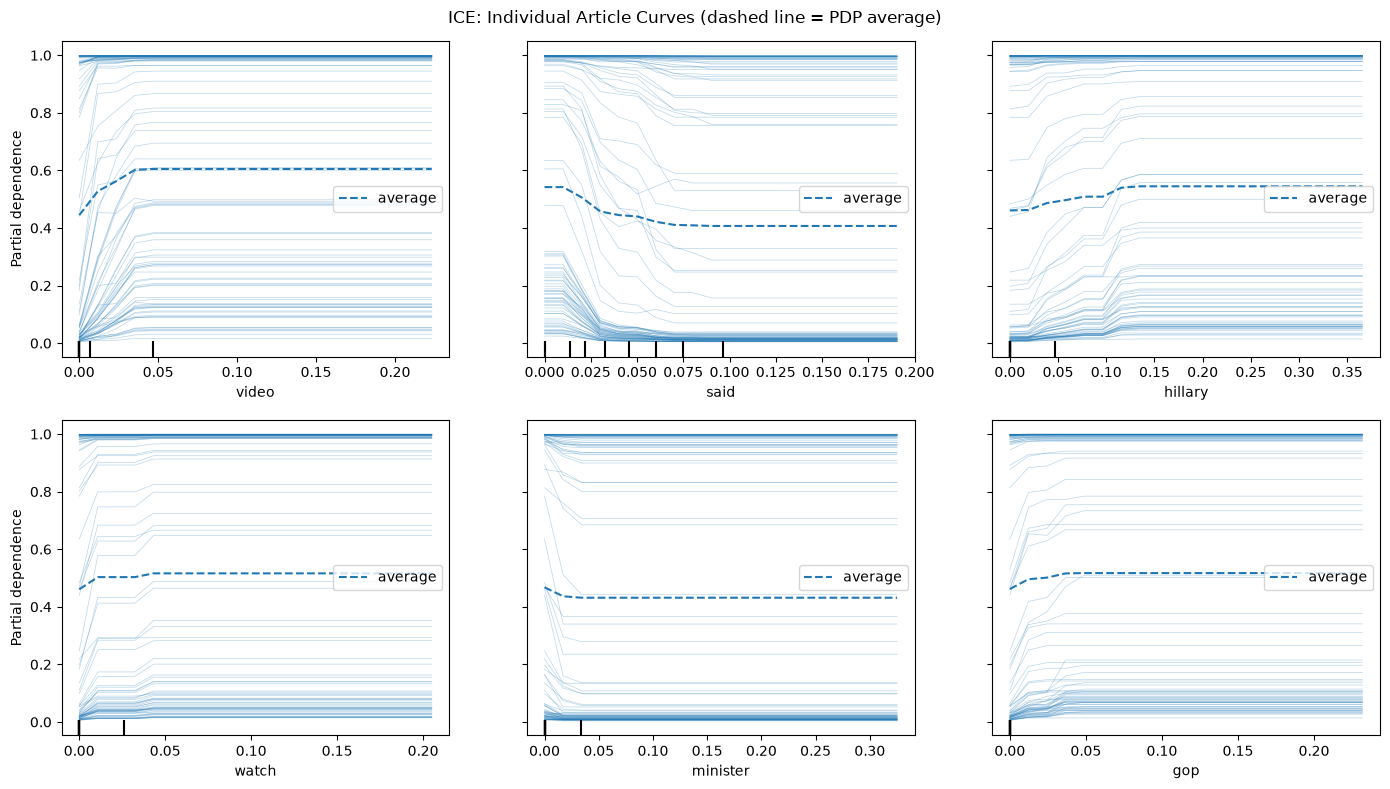

In [20]:
# ICE has no ALE version, so it only uses terms that are not part of any correlated pair
correlated_terms = {t for g in term_groups for t in g}
ice_idx = [i for i in top_idx if feature_names[i] not in correlated_terms][:6]
print("ICE terms:", list(feature_names[ice_idx]))

ice_display = PartialDependenceDisplay.from_estimator(
    lgbm, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the average. Many lines sit close to 0 or 1 and barely move: LightGBM is already very sure about those articles from their other words, so one word can't change much.

The lines in the middle move a lot more. Adding video can take an article from under 0.1 to over 0.6, and adding said can take one from 0.6 down to almost 0. The centered plot below shows the size of these changes more clearly.

### 11.1 Centered ICE

The ICE plot can be misleading. Each line starts at a different height, set by the article's other words, so a line that starts high and moves a little looks the same as one that starts low and moves a lot. That makes it hard to compare how much the term actually changes each article.

Centered ICE fixes this by shifting every line to start at 0. Each line then shows only the change in predicted probability when the term is added to that article, so the size of the effect can be compared directly across articles.

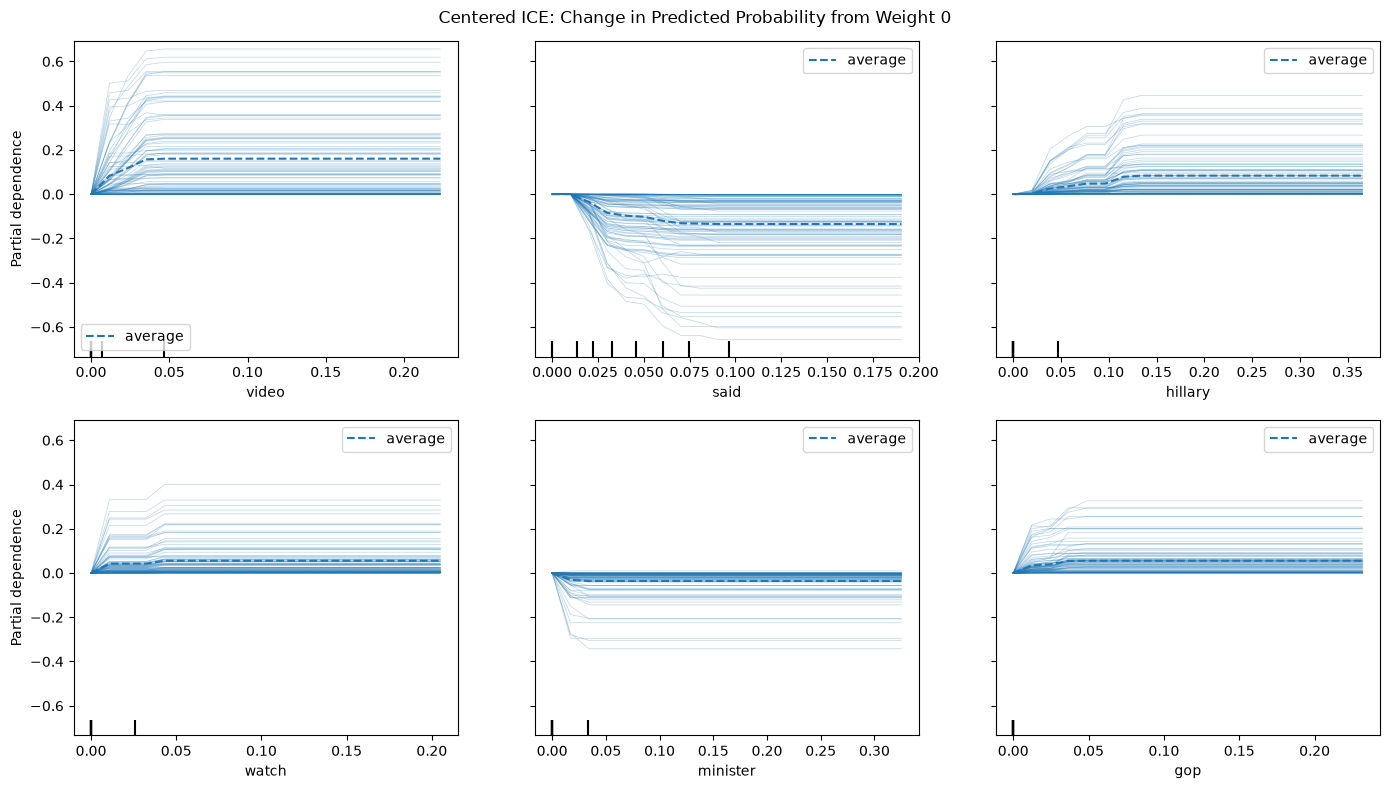

In [21]:
cice_display = PartialDependenceDisplay.from_estimator(
    lgbm, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in Predicted Probability from Weight 0")
plt.tight_layout()
plt.show()

Every panel goes one way only. Adding video raises articles by about 16 points on average and by up to 65 for some. said lowers them by about 13 on average and up to 65. hillary, watch and gop push up (by up to 45, 40 and 33 points), and minister pushes down (by up to 34).

The spread is much wider than in the Random Forest. Many lines stay near 0, because the model was already sure about those articles, while a few articles near the middle swing by more than half the scale. So the direction of each term is consistent, but whether it matters depends on how sure the model already was.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the model overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the model was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

In [22]:
from IPython.display import display

explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return lgbm.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = lgbm.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains 200 random test articles and picks the 5 whose explanations together cover the most words with the least repetition. It doesn't look at the label or subject, so we check those afterwards.

In [23]:
from lime.submodular_pick import SubmodularPick

N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None         
)
sp_idx = cand_idx[sp.V]   

In [24]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
        "subject": [df.loc[y_test.index[i], "subject"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

words = lambda e: {w for w, _ in e.as_list(label=1)}
picked_words = set().union(*[words(e) for e in sp.sp_explanations])
all_words = set().union(*[words(e) for e in sp.explanations])

,subject,true_label,P(fake),outcome
0,News,fake,0.987,"TP (fake, caught)"
1,US_News,fake,0.996,"TP (fake, caught)"
2,politics,fake,0.465,"FN (fake, missed)"
3,politicsNews,real,0.017,"TN (real, correct)"
4,politicsNews,real,0.017,"TN (real, correct)"


SP-LIME pick 1 | P(fake) = 0.987


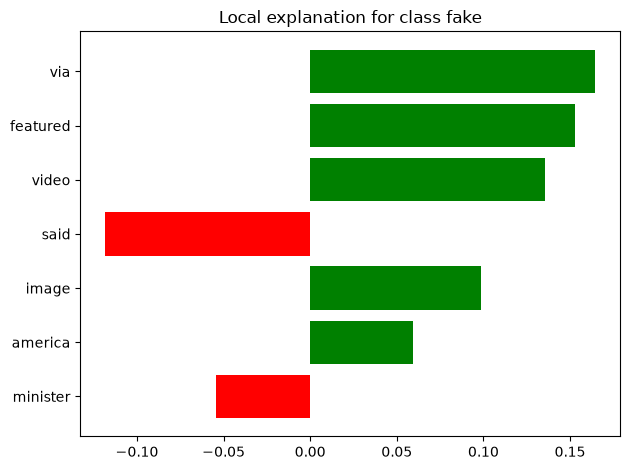

SP-LIME pick 2 | P(fake) = 0.996


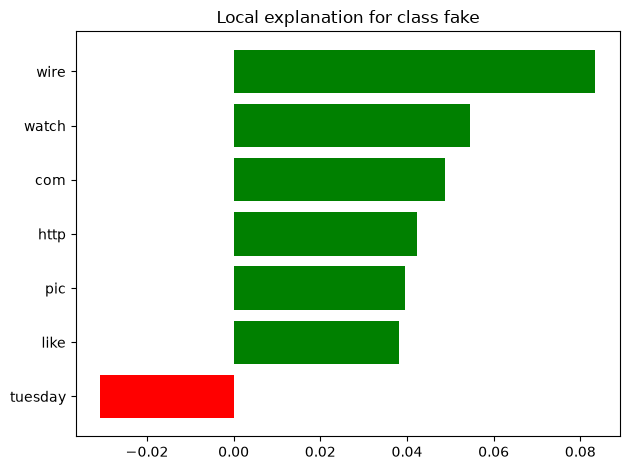

SP-LIME pick 3 | P(fake) = 0.465


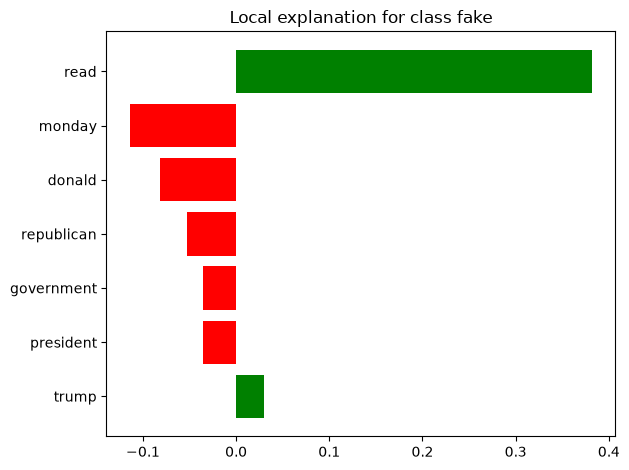

SP-LIME pick 4 | P(fake) = 0.017


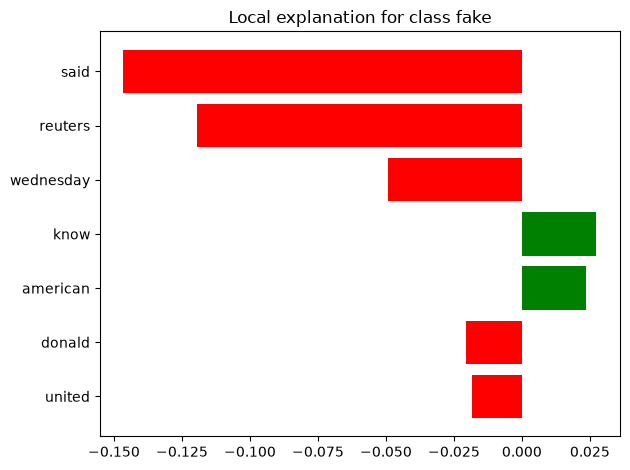

SP-LIME pick 5 | P(fake) = 0.017


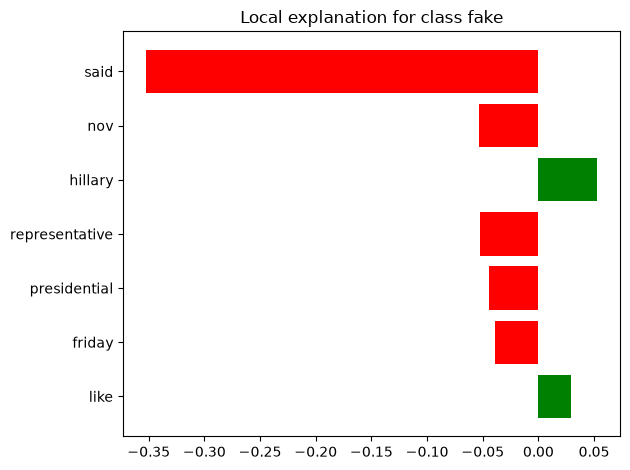

In [25]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

The picks are three fake articles and two real ones. The subject column just mirrors the label (see `dataset_eda.ipynb`). Four are very confident calls (0.987 and 0.996 for two fakes, 0.017 for both real ones), and one fake is missed at 0.465.

**Pick 1 (fake, 0.987).** via, featured, video and image push toward fake (about 0.10 to 0.17 each), against said and minister. Almost the whole fake side is the photo credit plus a video.

**Pick 2 (fake, 0.996).** wire (a site sign-off like "21st Century Wire"), watch, com, http and pic (an embedded tweet) push toward fake. Only tuesday pushes toward real.

**Pick 3 (fake, 0.465, missed).** read ("READ MORE") pushes hard toward fake (0.38), but monday, donald, republican, government and president pull toward real and just win. Without a photo credit, a fake article that names people formally and dates events like a news report slips under 0.5.

**Pick 4 (real, 0.017).** said (−0.15) and reuters (−0.12) do most of the work, with wednesday.

**Pick 5 (real, 0.017).** said alone pulls toward real by 0.36, with nov, representative, presidential and friday.

The fakes are caught on fingerprints (photo credit, site sign-offs, tweet links, "READ MORE"), and the real ones on Reuters' style, above all said.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the predicted probability changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | P(fake) = 1.000


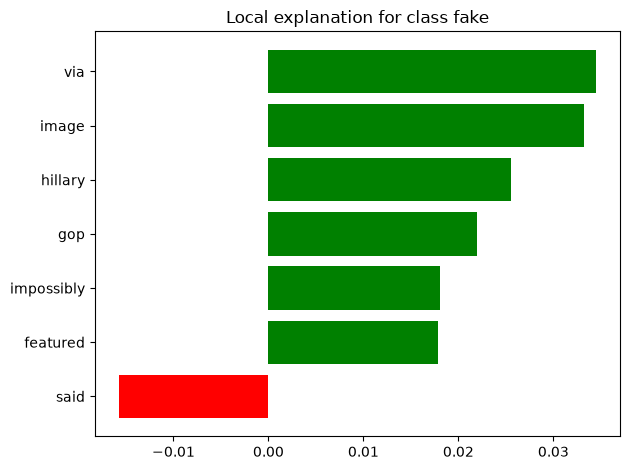

False Negative (fake, missed) | P(fake) = 0.017


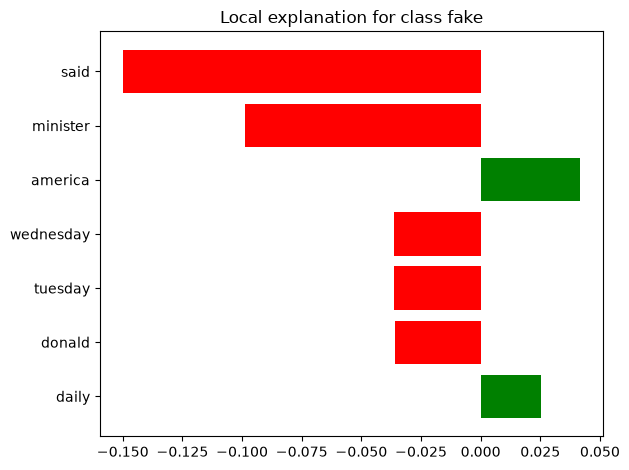

False Positive (real, flagged) | P(fake) = 0.928


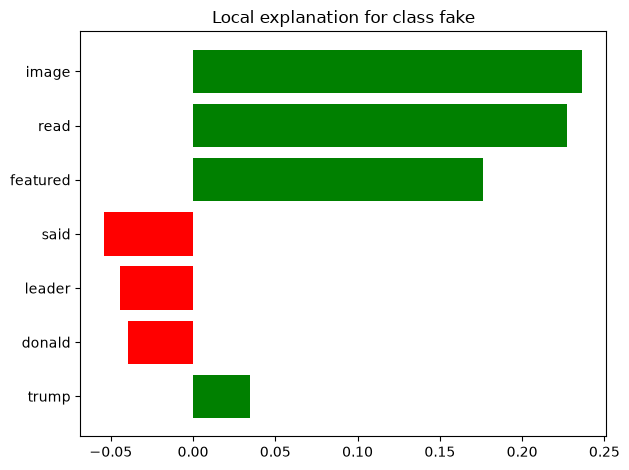

In [26]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

To see which articles these are, the cell below prints their headlines. The descriptions that follow refer to them.

In [27]:
for name, i in cases.items():
    print(name, "|", df.loc[y_test.index[i], "title"][:90])

True Positive (fake, caught) | Democracy Expert Tells Us EXACTLY How Republicans Screwed America By Accepting Trump
False Negative (fake, missed) | ISRAEL WILL NAME New Train Station Near Western Wall After President Donald Trump
False Positive (real, flagged) | 'Mad dog' anti-Trump leaflets, suspected floated in from North Korea, turn up in Seoul


These are the most extreme articles in each group.

**True Positive (P(fake) = 1.000).** The fake article ("Democracy Expert Tells Us EXACTLY How Republicans Screwed America By Accepting Trump") is caught on via, image, hillary, gop, impossibly and featured. All the weights are small (under 0.04), because the model is completely sure: removing a few words can't move a prediction of 1.000. The words still tell the story: the photo credit plus partisan naming.

**False Negative (P(fake) = 0.017).** The fake article ("ISRAEL WILL NAME New Train Station Near Western Wall After President Donald Trump") reads like a wire report. said (−0.15), minister (−0.10), wednesday, tuesday and donald pull toward real, and only america and daily push toward fake. Apart from the all-caps headline, the text quotes a minister and dates events the way Reuters does, and it has no photo credit, so the model is almost certain it's real.

**False Positive (P(fake) = 0.928).** This real Reuters article ("'Mad dog' anti-Trump leaflets, suspected floated in from North Korea, turn up in Seoul") is about leaflets, so it naturally talks about what the leaflets' images show and what they read. image, read and featured push toward fake (0.18 to 0.24 each), more than said, leader and donald can pull back. On fake sites these words come from photo credits and "READ MORE" links. Here they're used in their normal sense, and the model can't tell the difference.

Both errors come from the same habit: the model reacts to specific words, not to what they mean. A fake article that copies wire-report wording gets through, and a real article that happens to use "image" and "read" gets flagged.

LIME uses random samples, so results change a little between runs, especially for the smaller words.

### 12.3 SHAP Waterfall (the missed fake article)

LIME approximates the model around one article, while SHAP splits the model's own output into exact contributions. Here SHAP explains the missed fake article from 12.2, so the two methods can be compared on the same case. Values are in log-odds.

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


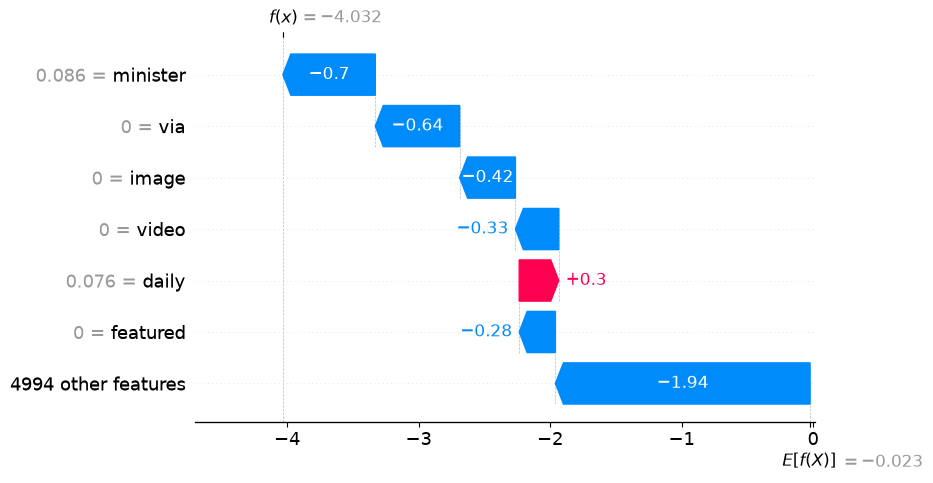

In [28]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at −0.023 log-odds (a probability of about 0.49), the model's average output, and ends at −4.03 (a probability of 0.017) for this missed fake.

minister pushes hardest toward real (−0.70). Then come three words the article doesn't have: via (−0.64), image (−0.42) and video (−0.33), with featured (−0.28) a bit further down. The missing photo credit alone (via, image and featured) adds about −1.3. daily is the only term pushing toward fake (+0.30). The other 4,994 terms add −1.94, about half the total.

SHAP and LIME agree that minister pulls strongly toward real and daily pushes toward fake. They disagree on said: it's LIME's biggest bar but isn't in SHAP's top six. And SHAP shows what LIME can't: the biggest reason for the miss, after minister, is the photo credit that isn't there.

### SHAP Waterfall (the other two articles)

To compare with LIME on all three articles, SHAP also explains the real article that was flagged and the fake article that was caught.

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


False Positive (real, flagged)


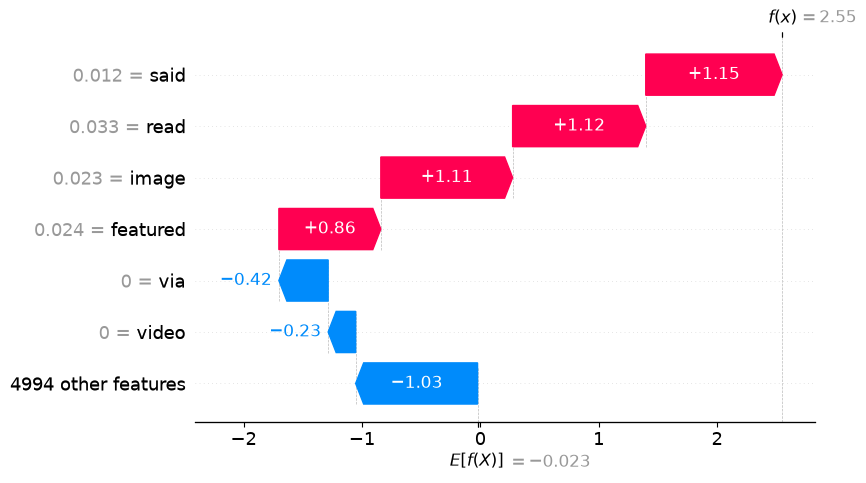

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


True Positive (fake, caught)


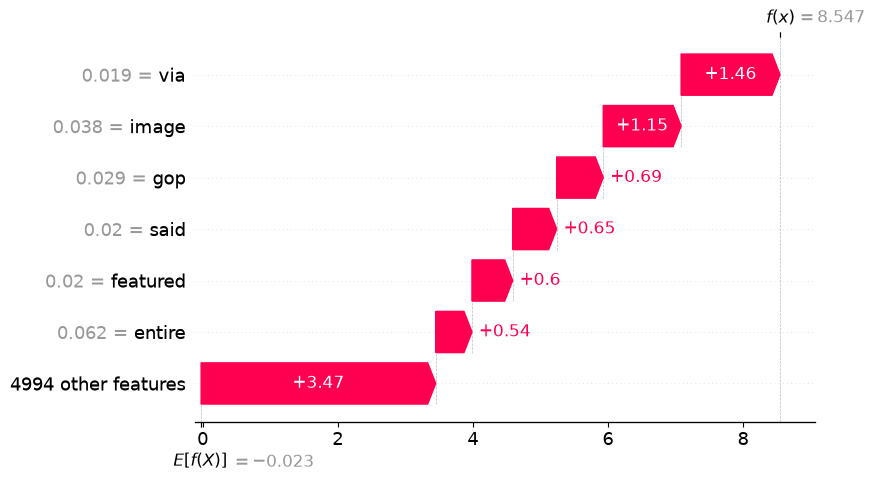

In [29]:
for name in ["False Positive (real, flagged)", "True Positive (fake, caught)"]:
    i = cases[name]
    x_one = X_test_dense[i:i + 1]

    sv_one = explainer_shap.shap_values(x_one, check_additivity=False)
    if isinstance(sv_one, list):
        sv_one = sv_one[1]
    elif np.ndim(sv_one) == 3:
        sv_one = sv_one[:, :, 1]

    print(name)
    shap.plots.waterfall(
        shap.Explanation(values=sv_one[0], base_values=base_value,
                         data=x_one[0], feature_names=list(feature_names)),
        max_display=7
    )

Both start at −0.023 log-odds, the model's average output.

**Real article flagged (False Positive).** It ends at 2.55 log-odds (a probability of about 0.93). Three of the four words pushing it toward fake are source fingerprints: "read" (+1.12), "image" (+1.11) and "featured" (+0.86). "said" appears only weakly (TF-IDF 0.012), and the model treats that as a fake signal too (+1.15). The missing "via" and "video" and the other 4,994 words pull back (−1.68 together), but not enough.

**Fake article caught (True Positive).** It ends at 8.55 log-odds (a probability above 0.999). "via" (+1.46), "image" (+1.15) and "featured" (+0.60) are all photo-credit words, joined by "gop" (+0.69) and a weak "said" (+0.65). Unlike the flagged real article, the other 4,994 words also push toward fake (+3.47), so everything points the same way.

So the real article was flagged because it carries the fake sites' page-layout words ("image", "featured", "read") and barely uses "said". That's the same pattern the model uses to catch real fakes.

## 13. Summary

LightGBM catches 96.6% of fake articles (recall 0.9659) with precision 0.990, accuracy 0.980 and ROC AUC 0.998. That matches the Logistic Regression baseline on accuracy and comes close on recall (0.969). It misses slightly more fakes than the baseline (119 vs 108) but raises fewer false alarms (35 vs 44), and it misses about half as many fakes as the Random Forest. Training and test recall are almost the same, so it isn't overfitting.

Several top terms come as packages, so we used grouped PFI instead of plain PFI and ALE instead of PDP. The methods agree on what LightGBM relies on:

- **Grouped PFI:** the photo-credit group matters most (recall drop 0.061, about 212 fake articles), well ahead of said (0.024), video and reuters. That's about three times the Random Forest's reliance on the photo credit.
- **TreeSHAP:** via and said are the strongest terms, and the absence of via pushes toward real.
- **ALE:** via alone moves the prediction by about 22 points. Once via is known, image and featured add little, since they come with it.
- **ICE:** each term pushes every article the same way, but articles the model is already sure about barely move, while uncertain ones can swing by more than half the scale.
- **LIME:** fakes are caught on fingerprints and real articles on said. The worst errors are a fake article written like a wire report and a real article about leaflets, flagged because it uses "image" and "read" in their normal sense.
- **SHAP waterfall (missed fake):** SHAP and LIME agree closely: company comes first, and five of SHAP's six words appear in LIME's list.
- **SHAP waterfall (flagged real and caught fake):** the real article was flagged because it contains photo-credit words ("image", "featured", "read") and barely uses "said", the same signals that catch the real fake.

So LightGBM is as accurate as the baseline, but it gets there by leaning hardest of all the models on the photo credit, a page-layout fingerprint of the fake sites. Its errors show the same limit as the other models: it judges how an article is written and laid out, not whether what it says is true.